# Agrupación de libros de biblioteca

![SENATI](../../04_RECURSOS/logo_senati.png)

**Actividad:** desarrollar una solución de aprendizaje no supervisado.  
**Dificultad:** intermedia, similar a las prácticas guiadas.  
**Datos:** simulados para clase.

## Situación de trabajo

Agrupar libros por préstamos, disponibilidad y páginas, sin inventar grupos antes del entrenamiento.

**Archivo:** `datos_biblioteca.csv`  
**Algoritmo sugerido:** K-Means con normalización

En este caso no encontrarás el programa terminado. El objetivo es que repitas la metodología de los ejemplos resueltos y expliques tus decisiones.

**Trabajo desarrollado por:** COCA CCORPA LORENA ABIGAIL  
**Institución:** SENATI · 2026  
**Actividad:** Agrupación de libros de biblioteca  
**Nota:** Los datos suministrados por el taller son simulados; los resultados y pruebas son cálculos realizados sobre esos CSV.

## Parte A. Leer el CSV y elegir los datos

Completa el código. Empieza mostrando cinco filas y verificando las columnas de entrenamiento.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza la lectura, entrenamiento y explicación del reto. Se conserva el enunciado original y el código se ejecuta en orden.</div>

In [1]:
from pathlib import Path
import pandas as pd

ruta = Path('datos_biblioteca.csv')
if not ruta.exists():
    ruta = Path('03_RETOS_ESTUDIANTES/RETO_01_BIBLIOTECA/datos_biblioteca.csv')

datos = pd.read_csv(ruta)
display(datos.head())

# TODO: elegir las columnas numéricas que se utilizarán.
columnas = ['prestamos_mes', 'ejemplares_disponibles', 'paginas']
X = datos[columnas]
print("Registros:", len(X))

,codigo_libro,prestamos_mes,ejemplares_disponibles,paginas
0,LIB037,6,55,153
1,LIB095,21,21,255
2,LIB043,2,49,106
3,LIB087,59,9,420
4,LIB047,13,40,298


Registros: 110


## Parte B. Entrenar y explicar

1. Crea el algoritmo recomendado.
2. Cuando corresponda, utiliza `StandardScaler`.
3. Entrena con `fit_predict()`.
4. Agrega la columna de grupo/alerta.
5. Muestra el número de registros por resultado.

Regresa al Proyecto 02 para agrupar o al Proyecto 04 para detectar registros poco habituales. Toma esos cuadernos como ejemplos, pero escribe tú la solución.

Resultados: {0: 32, 1: 37, 2: 41}
Valores medios por resultado:
           prestamos_mes  ejemplares_disponibles  paginas
resultado                                                
0                  35.44                    8.16   436.94
1                   5.19                   50.46   173.05
2                  19.02                   21.46   290.24


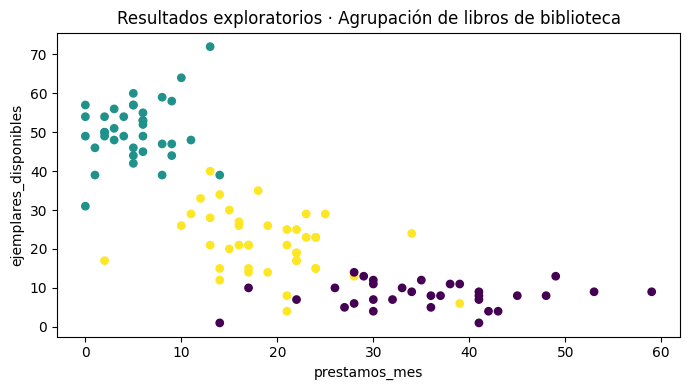

Nuevo caso de prueba: 1


In [2]:
# Entrenamiento reproducible: Agrupación de libros de biblioteca
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
CARACTERISTICAS = ['prestamos_mes', 'ejemplares_disponibles', 'paginas']
X = datos[CARACTERISTICAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
modelo = KMeans(n_clusters=3,random_state=42,n_init=10)
resultado = modelo.fit_predict(X_escalada)
datos['resultado'] = resultado
print('Resultados:',datos['resultado'].value_counts().sort_index().to_dict())
print('Valores medios por resultado:')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'kmeans'}, 'modelo_entrenado.joblib')
datos.to_csv('resultados.csv',index=False)
plt.figure(figsize=(7,4))
plt.scatter(datos[CARACTERISTICAS[0]],datos[CARACTERISTICAS[1]],c=resultado,cmap='viridis',s=28)
plt.xlabel(CARACTERISTICAS[0]);plt.ylabel(CARACTERISTICAS[1]);plt.title('Resultados exploratorios · '+ 'Agrupación de libros de biblioteca')
plt.tight_layout();plt.savefig('grafico_resultados.png',dpi=135);plt.show()
print('Nuevo caso de prueba:',modelo.predict(escalador.transform(X.iloc[[0]]))[0])


## Parte C. Aplicación y entrega

Crea `entrenar.py`, `app.py`, `templates/index.html` y `static/estilos.css`. La aplicación recibirá entradas numéricas en un formulario y mostrará el resultado del algoritmo, sin JavaScript.

### Evidencias

- CSV leído con Pandas.
- Tabla y gráfico con resultados.
- Una predicción nueva demostrada y explicada.
- Pantalla del formulario funcionando.
- Dos observaciones sobre las limitaciones del resultado.

### Preguntas para sustentar

1. ¿Por qué el problema es no supervisado?
2. ¿Por qué elegiste esas columnas?
3. ¿Por qué el algoritmo necesita (o no) normalizar los datos?
4. ¿Qué significa exactamente el resultado que muestra tu formulario?
5. ¿Qué pasaría si cambias uno de los valores ingresados?

**Rúbrica sugerida /20:** lectura de datos 4, preparación 4, algoritmo 5, formulario 4, explicación 3.

### Respuestas cortas

1. **¿Por qué no supervisado?** No hay una categoría de libro para enseñarle al algoritmo.
2. **¿Por qué esas columnas?** Préstamos, disponibilidad y páginas explican diferencias de uso.
3. **¿Por qué normalizar?** Los valores tienen escalas diferentes y K-Means usa distancias.
4. **¿Qué muestra la web?** Un grupo de libros parecidos, no una calidad superior.
5. **¿Qué ocurre si cambian los valores?** Puede asignar otro grupo.

### Interpretación de pruebas y límites del algoritmo

In [3]:
paquete=joblib.load('modelo_entrenado.joblib')
filas=datos[CARACTERISTICAS].iloc[:2].copy()
filas['prediccion']=paquete['modelo'].predict(paquete['escalador'].transform(filas))
print(filas.to_string(index=False))

 prestamos_mes  ejemplares_disponibles  paginas  prediccion
             6                      55      153           1
            21                      21      255           2


**K-Means:** Los números de grupo son identificadores arbitrarios, no puntuaciones de calidad. Se describen los promedios de cada grupo y se recuerda que cambiar el conjunto de entrenamiento puede alterar los centroides. El escalador utilizado al predecir es **exactamente el entrenado**; estos CSV son simulados.